# Лабораторная работа 1 — качество и дрейф данных и продуктовые метрики

**Задача ВКР.** Мониторинг отзывов о товарах: автоматически находить негативные отзывы, чтобы команда поддержки быстрее видела жалобы. Исследовательский вопрос: как временной сдвиг и ухудшение качества текста меняют качество классификации и нагрузку на обработку жалоб?

**Источник и условия использования.** [McAuley Lab, Amazon Reviews 2023, All_Beauty](https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023). Единица наблюдения — текст одного отзыва с рейтингом и timestamp.

## 1. Импорты

In [1]:
%pip -q install 'datasets>=3,<5' 'transformers>=4.46,<5' 'accelerate>=1,<2' 'bitsandbytes>=0.44' scikit-learn scipy pandas matplotlib seaborn pyarrow


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 74.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 48.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, re, gc, json, hashlib, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score, matthews_corrcoef, balanced_accuracy_score
from scipy.spatial.distance import jensenshannon
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

SEED = 42
np.random.seed(SEED)
assert torch.cuda.is_available(), 'Нужна среда Colab с GPU T4'
GPU_NAME = torch.cuda.get_device_name(0)
assert 'T4' in GPU_NAME.upper(), f'Выбрана {GPU_NAME}; переключите Colab на T4 GPU'
print('GPU:', GPU_NAME, '| CUDA:', torch.version.cuda)
OUT = Path('/content/lab_results'); OUT.mkdir(exist_ok=True)


GPU: Tesla T4 | CUDA: 13.0


## 2. Данные


In [3]:
REVISION = '749931181c9cdd70bfa6408d8fe8b4ddd6107248'
DATA_URL = (f'https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/{REVISION}/'
            'raw_review_All_Beauty/full-00000-of-00001.parquet')
raw = load_dataset('parquet', data_files={'full': DATA_URL}, split='full')
cols = ['rating', 'title', 'text', 'timestamp', 'parent_asin', 'verified_purchase']
df0 = raw.select_columns(cols).to_pandas()
print('Source:', DATA_URL)
print('Rows:', len(df0), 'Columns:', df0.columns.tolist())
print('Missing values:'); display(df0.isna().sum().to_frame('n_missing'))
print('Rating distribution:'); display(df0['rating'].value_counts(dropna=False).sort_index().to_frame('n'))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


raw_review_All_Beauty/full-00000-of-0000(…):   0%|          | 0.00/139M [00:00<?, ?B/s]

Generating full split: 0 examples [00:00, ? examples/s]

Source: https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/749931181c9cdd70bfa6408d8fe8b4ddd6107248/raw_review_All_Beauty/full-00000-of-00001.parquet
Rows: 701528 Columns: ['rating', 'title', 'text', 'timestamp', 'parent_asin', 'verified_purchase']
Missing values:


,n_missing
rating,0
title,0
text,0
timestamp,0
parent_asin,0
verified_purchase,0


Rating distribution:


,n
rating,
1.0,102080
2.0,43034
3.0,56307
4.0,79381
5.0,420726


In [4]:
def normalize_text(s):
    return re.sub(r'\s+', ' ', str(s).casefold()).strip()

df = df0.copy()
df['title'] = df['title'].fillna('').astype(str)
df['text'] = df['text'].fillna('').astype(str)
df['review'] = (df['title'].str.strip() + '. ' + df['text'].str.strip()).str.strip(' .')
df['key'] = df['review'].map(normalize_text)
df['date'] = pd.to_datetime(df['timestamp'], unit='ms', utc=True, errors='coerce')
df['label'] = np.where(df['rating'].isin([1, 2]), 'NEGATIVE',
                       np.where(df['rating'].isin([4, 5]), 'POSITIVE', None))
audit = {
    'raw_rows': len(df),
    'missing_text': int(df0['text'].isna().sum()),
    'missing_timestamp': int(df['date'].isna().sum()),
    'exact_duplicate_texts': int(df['key'].duplicated().sum()),
    'ambiguous_3_star': int((df['rating'] == 3).sum()),
    'too_short_lt_12_chars': int((df['key'].str.len() < 12).sum()),
}
valid = df['date'].notna() & df['label'].notna() & (df['key'].str.len() >= 12)
df = df.loc[valid].copy()
conflict_keys = df.groupby('key')['label'].nunique().loc[lambda s: s > 1].index
audit['conflicting_text_keys'] = len(conflict_keys)
df = df.loc[~df['key'].isin(conflict_keys)].drop_duplicates('key', keep='first')
df = df.sort_values(['date','key']).reset_index(drop=True)
audit['clean_rows'] = len(df)
display(pd.Series(audit, name='value').to_frame())
display(df.groupby(df['date'].dt.year)['label'].value_counts().unstack(fill_value=0).tail(15))
print('Period:', df['date'].min(), '—', df['date'].max())
assert len(df) > 10000 and df['label'].nunique() == 2


,value
raw_rows,701528
missing_text,0
missing_timestamp,0
exact_duplicate_texts,33861
ambiguous_3_star,56307
too_short_lt_12_chars,3481
conflicting_text_keys,48
clean_rows,611811


label,NEGATIVE,POSITIVE
date,,
2009,190,924
2010,249,1194
2011,367,1313
2012,470,2073
2013,1112,6057
2014,2238,11571
2015,5099,24944
2016,9503,42582
2017,12158,44248


Period: 2000-11-01 04:24:18+00:00 — 2023-09-09 00:39:36.666000+00:00


In [5]:
n = len(df)
train_pool = df.iloc[:int(.60*n)].copy()
val_pool   = df.iloc[int(.60*n):int(.75*n)].copy()
test_pool  = df.iloc[int(.75*n):int(.85*n)].copy()
new_pool   = df.iloc[int(.85*n):].copy()

def balanced_sample(frame, n, seed):
    k = n // 2
    pieces = [frame.loc[frame.label.eq(label)].sample(n=k, random_state=seed)
              for label in ['NEGATIVE','POSITIVE']]
    return pd.concat(pieces).sample(frac=1, random_state=seed).reset_index(drop=True)

shots = balanced_sample(train_pool, 4, SEED)
val = balanced_sample(val_pool, 60, SEED + 1)
test = balanced_sample(test_pool, 120, SEED + 2)
new = new_pool.sample(n=240, random_state=SEED + 3).reset_index(drop=True)  # natural prevalence

# Проверка почти одинаковых текстов на всех текстах, реально входящих в эксперимент.
# Для пары с cosine similarity > 0.97 оставляем более ранний split/первое наблюдение.
sampled = pd.concat([shots.assign(split='shots'), val.assign(split='validation'),
                     test.assign(split='test'), new.assign(split='new')], ignore_index=True)
vec = TfidfVectorizer(analyzer='char', ngram_range=(3,5), min_df=1, max_features=50000)
X = vec.fit_transform(sampled['key'])
S = (X @ X.T).tocsr()
drop = set(); near_pairs = 0
for i in range(S.shape[0]):
    if i in drop: continue
    start, end = S.indptr[i], S.indptr[i+1]
    for j, sim in zip(S.indices[start:end], S.data[start:end]):
        if j > i and sim > .97:
            drop.add(int(j)); near_pairs += 1
sampled = sampled.drop(index=list(drop)).reset_index(drop=True)
shots, val, test, new = [sampled.loc[sampled.split.eq(s)].reset_index(drop=True)
                         for s in ['shots','validation','test','new']]
print('Near-duplicate later rows removed:', near_pairs)
display(pd.DataFrame([{'split': name, 'n': len(part), 'start': part.date.min(),
                       'end': part.date.max(), 'negative_share': part.label.eq('NEGATIVE').mean()}
                      for name,part in [('train_pool',train_pool),('validation',val),('test',test),('new',new)]]))
assert len(shots) == 4 and min(len(val),len(test),len(new)) > 40
assert max(train_pool.date) <= min(val_pool.date) <= min(test_pool.date) <= min(new_pool.date)
assert not set(shots.key) & set(val.key) and not set(val.key) & set(test.key)


Near-duplicate later rows removed: 0


,split,n,start,end,negative_share
0,train_pool,367086,2000-11-01 04:24:18+00:00,2020-06-15 14:53:34.724000+00:00,0.207218
1,validation,60,2020-06-18 03:35:27.722000+00:00,2021-03-06 13:40:43.074000+00:00,0.500000
2,test,120,2021-03-10 15:41:35.893000+00:00,2021-09-10 22:22:20.748000+00:00,0.500000
3,new,240,2021-09-13 01:18:06.111000+00:00,2023-08-15 01:37:12.585000+00:00,0.329167


## 3. Измерение временного дрейфа

Сравниваются реальные периоды validation, test и поздний новый срез. PSI вычисляется для длины текста, Jensen–Shannon distance — для распределения 1000 наиболее частых слов. PSI и JS показывают изменение распределения; сами по себе не доказывают ухудшение качества и не задают универсального порога тревоги. Для контрольного эксперимента ниже повреждение текста создается отдельно на **тех же объектах**, поэтому изменение метрик можно связать именно с повреждением при фиксированной метке.


,comparison,length_PSI,word_JS_distance,negative_share_val,negative_share_current
0,validation → test,0.036779,0.184677,0.242,0.276
1,validation → new,0.053426,0.188244,0.242,0.289


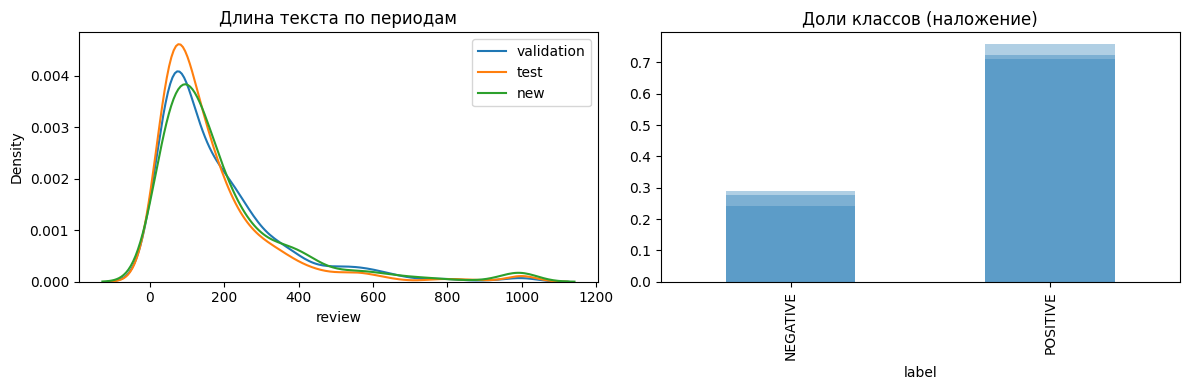

In [6]:
def psi_numeric(reference, current, bins=10):
    edges = np.unique(np.quantile(reference, np.linspace(0,1,bins+1)))
    if len(edges) < 3: return float('nan')
    edges[0], edges[-1] = -np.inf, np.inf
    a = np.histogram(reference, bins=edges)[0].astype(float)
    b = np.histogram(current, bins=edges)[0].astype(float)
    a = np.clip(a/a.sum(), 1e-6, 1); b = np.clip(b/b.sum(), 1e-6, 1)
    return float(np.sum((b-a)*np.log(b/a)))

natural_val = val_pool.sample(n=min(1000,len(val_pool)), random_state=SEED+20)
natural_test = test_pool.sample(n=min(1000,len(test_pool)), random_state=SEED+21)
natural_new = new_pool.sample(n=min(1000,len(new_pool)), random_state=SEED+22)
bow = CountVectorizer(max_features=1000, stop_words='english', min_df=2)
bow.fit(pd.concat([natural_val.review, natural_test.review, natural_new.review]).str.slice(0,1200))
def js_words(a,b):
    ca = np.asarray(bow.transform(a.str.slice(0,1200)).sum(axis=0)).ravel() + 1
    cb = np.asarray(bow.transform(b.str.slice(0,1200)).sum(axis=0)).ravel() + 1
    return float(jensenshannon(ca/ca.sum(), cb/cb.sum(), base=2))

drift = pd.DataFrame([
    {'comparison': name, 'length_PSI': psi_numeric(natural_val.review.str.len(), part.review.str.len()),
     'word_JS_distance': js_words(natural_val.review, part.review),
     'negative_share_val': natural_val.label.eq('NEGATIVE').mean(),
     'negative_share_current': part.label.eq('NEGATIVE').mean()}
    for name,part in [('validation → test',natural_test),('validation → new',natural_new)]])
display(drift)
fig, axes = plt.subplots(1,2,figsize=(12,4))
for name,part in [('validation',natural_val),('test',natural_test),('new',natural_new)]:
    sns.kdeplot(part.review.str.len().clip(upper=1000), label=name, ax=axes[0])
    part.label.value_counts(normalize=True).rename(name).reindex(['NEGATIVE','POSITIVE']).plot(kind='bar', ax=axes[1], alpha=.35)
axes[0].legend(); axes[0].set_title('Длина текста по периодам'); axes[1].set_title('Доли классов (наложение)')
plt.tight_layout(); plt.show()

## 4. LLM

Одинаковые правила, формат `NEGATIVE`/`POSITIVE`, объекты и few-shot примеры. Температура 0, жадная генерация, максимум 6 новых токенов. Невалидный ответ учитывается отдельно и как ошибка классификации. Перед основным сравнением 60 объектов validation помогают выбрать модель/режим. Затем все шесть комбинаций проверяются на одном нетронутом test. Модель для позднего среза выбирается **по validation**, без подбора по test.


In [7]:
MODELS = [
    'Qwen/Qwen2.5-3B-Instruct',
    'Qwen/Qwen2.5-1.5B-Instruct',
    'HuggingFaceTB/SmolLM2-1.7B-Instruct',
]
LABELS = ['NEGATIVE','POSITIVE']
SYSTEM = ('Classify the sentiment expressed in this product review. '
          'Return exactly one uppercase label: NEGATIVE or POSITIVE. '
          'NEGATIVE means dissatisfaction, complaints or problems. '
          'POSITIVE means satisfaction or praise. Do not output explanations.')

def make_messages(review, few_shot=False):
    messages = [{'role':'system','content':SYSTEM}]
    if few_shot:
        for r in shots.itertuples():
            messages += [{'role':'user','content':'Review: ' + r.review[:450]},
                         {'role':'assistant','content':r.label}]
    messages += [{'role':'user','content':'Review: ' + review[:1200]}]
    return messages

def load_model(model_id):
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    tok = AutoTokenizer.from_pretrained(model_id, trust_remote_code=False)
    if tok.pad_token_id is None: tok.pad_token = tok.eos_token
    q = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                           bnb_4bit_compute_dtype=torch.float16)
    model = AutoModelForCausalLM.from_pretrained(
        model_id, quantization_config=q, device_map='auto', torch_dtype=torch.float16,
        trust_remote_code=False, low_cpu_mem_usage=True)
    model.eval()
    return tok, model

def predict_one(tok, model, review, few_shot):
    prompt = tok.apply_chat_template(make_messages(review, few_shot), tokenize=False,
                                      add_generation_prompt=True)
    inputs = tok(prompt, return_tensors='pt', truncation=True, max_length=1024).to('cuda')
    torch.cuda.synchronize(); start = time.perf_counter()
    with torch.inference_mode():
        out = model.generate(**inputs, max_new_tokens=6, do_sample=False,
                             pad_token_id=tok.eos_token_id)
    torch.cuda.synchronize(); latency = time.perf_counter()-start
    answer = tok.decode(out[0][inputs['input_ids'].shape[1]:], skip_special_tokens=True).strip()
    match = re.fullmatch(r'(NEGATIVE|POSITIVE)[.!]?', answer.upper())
    return {'prediction':match.group(1) if match else 'INVALID', 'raw_answer':answer,
            'latency_s':latency, 'input_tokens':int(inputs['input_ids'].shape[1]),
            'output_tokens':int(out.shape[1]-inputs['input_ids'].shape[1])}

def run_slice(tok, model, frame, model_id, few_shot, split):
    rows = []
    for r in frame.itertuples():
        result = predict_one(tok, model, r.review, few_shot)
        rows.append({'split':split, 'model':model_id, 'mode':'few-shot' if few_shot else 'zero-shot',
                     'key_sha256':hashlib.sha256(r.key.encode()).hexdigest(), 'date':r.date.isoformat(),
                     'true_label':r.label, **result})
    return pd.DataFrame(rows)

def score(frame):
    y, p = frame.true_label, frame.prediction
    yn, pn = y.eq('NEGATIVE'), p.eq('NEGATIVE')
    return {'n':len(frame),
            'macro_f1':f1_score(y,p,labels=LABELS,average='macro',zero_division=0),
            'negative_f1':f1_score(yn,pn,zero_division=0),
            'negative_precision':precision_score(yn,pn,zero_division=0),
            'negative_recall':recall_score(yn,pn,zero_division=0),
            'invalid_rate':p.eq('INVALID').mean(),
            'p95_latency_s':frame.latency_s.quantile(.95),
            'peak_gpu_GB':frame.peak_gpu_GB.max() if 'peak_gpu_GB' in frame else np.nan,
            'input_tokens':frame.input_tokens.sum(), 'output_tokens':frame.output_tokens.sum()}


In [8]:
all_results = []
for model_id in MODELS:
    print('Loading', model_id, flush=True)
    tok, model = load_model(model_id)
    for split, frame in [('validation',val),('test',test)]:
        for few_shot in [False,True]:
            filename = OUT / f'{model_id.split("/")[-1]}_{split}_{"few" if few_shot else "zero"}.csv'
            if filename.exists():
                result = pd.read_csv(filename)
            else:
                print(model_id, split, 'few-shot' if few_shot else 'zero-shot', len(frame), flush=True)
                result = run_slice(tok, model, frame, model_id, few_shot, split)
                result['peak_gpu_GB'] = torch.cuda.max_memory_allocated()/1e9
                result.to_csv(filename,index=False)
            all_results.append(result)
    del tok, model; gc.collect(); torch.cuda.empty_cache()
results = pd.concat(all_results, ignore_index=True)
table = pd.DataFrame([{'model':m,'mode':mode,'split':split, **score(g)}
                      for (m,mode,split),g in results.groupby(['model','mode','split'])])
display(table.sort_values(['split','macro_f1'], ascending=[True,False]))
table.to_csv(OUT/'model_comparison.csv',index=False)


Loading Qwen/Qwen2.5-3B-Instruct


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

config.json:   0%|          | 0.00/908 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.42G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

HuggingFaceTB/SmolLM2-1.7B-Instruct validation zero-shot 60
HuggingFaceTB/SmolLM2-1.7B-Instruct validation few-shot 60
HuggingFaceTB/SmolLM2-1.7B-Instruct test zero-shot 120
HuggingFaceTB/SmolLM2-1.7B-Instruct test few-shot 120


,model,mode,split,n,macro_f1,negative_f1,negative_precision,negative_recall,invalid_rate,p95_latency_s,peak_gpu_GB,input_tokens,output_tokens
4,Qwen/Qwen2.5-1.5B-Instruct,few-shot,test,120,0.966657,0.967213,0.951613,0.983333,0.0,0.221662,1.292412,33548,360
6,Qwen/Qwen2.5-1.5B-Instruct,zero-shot,test,120,0.958261,0.960000,0.923077,1.000000,0.0,0.198575,1.282511,13388,360
0,HuggingFaceTB/SmolLM2-1.7B-Instruct,few-shot,test,120,0.941663,0.942149,0.934426,0.950000,0.0,0.234084,1.287048,36627,480
8,Qwen/Qwen2.5-3B-Instruct,few-shot,test,120,0.941467,0.944882,0.895522,1.000000,0.0,0.368987,3.084911,33548,360
10,Qwen/Qwen2.5-3B-Instruct,zero-shot,test,120,0.924576,0.930233,0.869565,1.000000,0.0,0.274240,3.084911,13388,360
2,HuggingFaceTB/SmolLM2-1.7B-Instruct,zero-shot,test,120,0.874991,0.873950,0.881356,0.866667,0.0,0.203082,1.255003,14307,480
1,HuggingFaceTB/SmolLM2-1.7B-Instruct,few-shot,validation,60,0.949986,0.949153,0.965517,0.933333,0.0,0.220940,1.255003,17764,240
3,HuggingFaceTB/SmolLM2-1.7B-Instruct,zero-shot,validation,60,0.949986,0.950820,0.935484,0.966667,0.0,0.185233,1.209008,6604,240
5,Qwen/Qwen2.5-1.5B-Instruct,few-shot,validation,60,0.949986,0.950820,0.935484,0.966667,0.0,0.194615,1.282511,16213,180
7,Qwen/Qwen2.5-1.5B-Instruct,zero-shot,validation,60,0.949875,0.952381,0.909091,1.000000,0.0,0.180880,1.276447,6133,180


In [9]:
# Правило выбора объявлено заранее: macro-F1 на validation, затем recall NEGATIVE,
# затем меньшая доля невалидных ответов. Test в выборе не участвует.
selection = table.loc[table.split.eq('validation')].sort_values(
    ['macro_f1','negative_recall','invalid_rate'], ascending=[False,False,True])
winner = selection.iloc[0]
BEST_MODEL, BEST_MODE = winner['model'], winner['mode']
print('Выбраны по validation:', BEST_MODEL, BEST_MODE)
test_best = results.loc[results.split.eq('test') & results.model.eq(BEST_MODEL) & results['mode'].eq(BEST_MODE)]
display(pd.DataFrame(confusion_matrix(test_best.true_label,test_best.prediction,
                                      labels=['NEGATIVE','POSITIVE','INVALID']),
                     index=['true NEGATIVE','true POSITIVE','true INVALID'],
                     columns=['pred NEGATIVE','pred POSITIVE','pred INVALID']))
display(test_best.loc[test_best.true_label.ne(test_best.prediction),
                      ['true_label','prediction','raw_answer','date']].head(10))
# Для содержательного анализа показываем тексты только в текущем Colab,
# но не сохраняем их в CSV или summary.json.
test_view = test.copy()
test_view['key_sha256'] = test_view.key.map(lambda s: hashlib.sha256(s.encode()).hexdigest())
errors = test_best.loc[test_best.true_label.ne(test_best.prediction)].merge(
    test_view[['key_sha256','rating','review']], on='key_sha256', how='left')
errors['review_excerpt'] = errors.review.str.slice(0,240)
display(errors[['rating','true_label','prediction','raw_answer','review_excerpt']].head(10))
print('Типы ошибок на общем test:')
display(pd.crosstab(test_best.true_label,test_best.prediction))


Выбраны по validation: HuggingFaceTB/SmolLM2-1.7B-Instruct zero-shot


,pred NEGATIVE,pred POSITIVE,pred INVALID
true NEGATIVE,52,8,0
true POSITIVE,7,53,0
true INVALID,0,0,0


,true_label,prediction,raw_answer,date
854,POSITIVE,NEGATIVE,NEGATIVE,2021-07-30T10:11:59.689000+00:00
858,POSITIVE,NEGATIVE,NEGATIVE,2021-03-11T12:53:28.892000+00:00
859,POSITIVE,NEGATIVE,NEGATIVE,2021-04-30T00:45:01.797000+00:00
865,NEGATIVE,POSITIVE,POSITIVE,2021-09-08T00:10:43.016000+00:00
871,POSITIVE,NEGATIVE,NEGATIVE,2021-04-21T18:01:41.523000+00:00
875,POSITIVE,NEGATIVE,NEGATIVE,2021-08-10T16:38:33.167000+00:00
883,POSITIVE,NEGATIVE,NEGATIVE,2021-06-20T21:16:12.554000+00:00
886,NEGATIVE,POSITIVE,POSITIVE,2021-06-13T14:34:25.811000+00:00
903,NEGATIVE,POSITIVE,POSITIVE,2021-04-26T16:43:50.004000+00:00
917,NEGATIVE,POSITIVE,POSITIVE,2021-07-15T03:09:42.846000+00:00


Типы ошибок на общем test:


prediction,NEGATIVE,POSITIVE
true_label,,
NEGATIVE,52,8
POSITIVE,7,53


## 5. Применение лучшей модели и влияние качества данных

Поздний срез содержит до 240 отзывов, то есть больше общего test (до 120). Он берется с естественной долей негативных отзывов. Повреждение воспроизводимо и применяется к 10% и 30% объектов: у выбранных текстов оставляются только первые 15% символов (минимум 12). Метки и состав объектов не меняются. Это имитация потери текста в потоке данных, а не утверждение о том, что такое повреждение действительно встречалось в исходном наборе.

**Операционные продуктовые прокси** на 1000 отзывов: пропущенные жалобы `FN/n × 1000`, лишние сигналы `FP/n × 1000`, доля сигналов, precision/recall по негативному классу. Условная стоимость = `5 × FN + 1 × FP` на 1000 отзывов. Вес 5:1 задан как сценарий, не является реальной денежной ценой. Невалидные ответы считаются пропущенными жалобами, если отзыв негативный.


In [10]:
def corrupt(frame, fraction, seed):
    copy = frame.copy().reset_index(drop=True)
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(copy), size=round(fraction*len(copy)), replace=False)
    for i in idx:
        s = copy.at[i,'review']
        copy.at[i,'review'] = s[:max(12,round(.15*len(s)))]
    return copy

new_slices = [('clean',new),('truncated_10pct',corrupt(new,.10,SEED+10)),
              ('truncated_30pct',corrupt(new,.30,SEED+30))]
tok, model = load_model(BEST_MODEL)
new_results = []
for name, frame in new_slices:
    filename = OUT/f'best_new_{name}.csv'
    if filename.exists():
        r = pd.read_csv(filename)
    else:
        print('Later slice:', name, len(frame), flush=True)
        r = run_slice(tok, model, frame, BEST_MODEL, BEST_MODE == 'few-shot', name)
        r['peak_gpu_GB'] = torch.cuda.max_memory_allocated()/1e9
        r.to_csv(filename,index=False)
    new_results.append(r)
del tok,model; gc.collect(); torch.cuda.empty_cache()
new_results = pd.concat(new_results, ignore_index=True)

def product_metrics(g):
    y,p = g.true_label,g.prediction
    fn = ((y=='NEGATIVE') & (p!='NEGATIVE')).sum()
    fp = ((y=='POSITIVE') & (p=='NEGATIVE')).sum()
    n = len(g)
    return {'n':n, 'true_negative_share':(y=='NEGATIVE').mean(),
            'alert_share':(p=='NEGATIVE').mean(),
            'missed_complaints_per_1000':1000*fn/n,
            'false_alerts_per_1000':1000*fp/n,
            'cost_units_per_1000':1000*(5*fn+fp)/n}

new_table = pd.DataFrame([{'scenario':name, **score(g), **product_metrics(g)}
                          for name,g in new_results.groupby('split',sort=False)])
display(new_table)
new_table.to_csv(OUT/'drift_quality_product_metrics.csv',index=False)


Later slice: clean 240
Later slice: truncated_10pct 240
Later slice: truncated_30pct 240


,scenario,n,macro_f1,negative_f1,negative_precision,negative_recall,invalid_rate,p95_latency_s,peak_gpu_GB,input_tokens,output_tokens,true_negative_share,alert_share,missed_complaints_per_1000,false_alerts_per_1000,cost_units_per_1000
0,clean,240,0.911749,0.883436,0.857143,0.911392,0.0,0.180321,1.221343,25761,960,0.329167,0.350000,29.166667,50.000000,195.833333
1,truncated_10pct,240,0.901252,0.867925,0.862500,0.873418,0.0,0.179561,1.221343,24745,960,0.329167,0.333333,41.666667,45.833333,254.166667
2,truncated_30pct,240,0.831349,0.763889,0.846154,0.696203,0.0,0.178296,1.221343,23227,960,0.329167,0.270833,100.000000,41.666667,541.666667


## 6. Многокритериальная оценка и стоимость

Для локального запуска на T4 **расход API равен нулю**, поскольку API не вызывается. Чтобы оценить возможную цену переноса на платный API, ниже задаются изменяемые тарифы за 1 млн входных и выходных токенов; значения по умолчанию оставлены нулевыми до выбора конкретного провайдера. Подставление текущих официальных тарифов дает сравнимую оценку на 1000 отзывов. Задержка и память измерены в данном Colab, не являются гарантией для другой среды.


In [11]:
API_INPUT_USD_PER_M = 0.0   # заполнить по официальному тарифу выбранного API
API_OUTPUT_USD_PER_M = 0.0
cost = table.loc[table.split.eq('test')].copy()
cost['api_usd_per_1000'] = 1000*(cost.input_tokens*API_INPUT_USD_PER_M +
                                  cost.output_tokens*API_OUTPUT_USD_PER_M)/(1e6*cost.n)
cost['local_api_spend_usd'] = 0.0
display(cost[['model','mode','macro_f1','negative_recall','invalid_rate',
              'p95_latency_s','peak_gpu_GB','api_usd_per_1000','local_api_spend_usd']]
        .sort_values('macro_f1',ascending=False))


,model,mode,macro_f1,negative_recall,invalid_rate,p95_latency_s,peak_gpu_GB,api_usd_per_1000,local_api_spend_usd
4,Qwen/Qwen2.5-1.5B-Instruct,few-shot,0.966657,0.983333,0.0,0.221662,1.292412,0.0,0.0
6,Qwen/Qwen2.5-1.5B-Instruct,zero-shot,0.958261,1.000000,0.0,0.198575,1.282511,0.0,0.0
0,HuggingFaceTB/SmolLM2-1.7B-Instruct,few-shot,0.941663,0.950000,0.0,0.234084,1.287048,0.0,0.0
8,Qwen/Qwen2.5-3B-Instruct,few-shot,0.941467,1.000000,0.0,0.368987,3.084911,0.0,0.0
10,Qwen/Qwen2.5-3B-Instruct,zero-shot,0.924576,1.000000,0.0,0.274240,3.084911,0.0,0.0
2,HuggingFaceTB/SmolLM2-1.7B-Instruct,zero-shot,0.874991,0.866667,0.0,0.203082,1.255003,0.0,0.0


In [12]:
# Вывод строится из измеренных результатов; текст не содержит демонстрационных чисел.
clean = new_table.loc[new_table.scenario.eq('clean')].iloc[0]
bad = new_table.loc[new_table.scenario.eq('truncated_30pct')].iloc[0]
delta_missed = bad.missed_complaints_per_1000 - clean.missed_complaints_per_1000
print(f'Вывод. На общем test лучшая по validation комбинация {BEST_MODEL}, {BEST_MODE}, '
      f'получила macro-F1={score(test_best)["macro_f1"]:.3f} и recall негативного класса='
      f'{score(test_best)["negative_recall"]:.3f}.')
print(f'На позднем срезе: macro-F1={clean.macro_f1:.3f}; '
      f'пропущенные жалобы={clean.missed_complaints_per_1000:.1f} на 1000 отзывов.')
print(f'При повреждении 30% текстов: macro-F1={bad.macro_f1:.3f}; '
      f'пропущенные жалобы={bad.missed_complaints_per_1000:.1f} на 1000 '
      f'(разница {delta_missed:+.1f}).')

summary = {'dataset_url':DATA_URL, 'gpu':GPU_NAME, 'seed':SEED,
           'best_model':BEST_MODEL, 'best_mode':BEST_MODE,
           'audit':audit, 'comparison':table.to_dict(orient='records'),
           'drift':drift.to_dict(orient='records'),
           'product_metrics':new_table.to_dict(orient='records')}
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,default=str))
print('Артефакты:', [p.name for p in OUT.iterdir()])


Вывод. На общем test лучшая по validation комбинация HuggingFaceTB/SmolLM2-1.7B-Instruct, zero-shot, получила macro-F1=0.875 и recall негативного класса=0.867.
На позднем срезе: macro-F1=0.912; пропущенные жалобы=29.2 на 1000 отзывов.
При повреждении 30% текстов: macro-F1=0.831; пропущенные жалобы=100.0 на 1000 (разница +70.8).
Артефакты: ['Qwen2.5-3B-Instruct_validation_zero.csv', 'drift_quality_product_metrics.csv', 'SmolLM2-1.7B-Instruct_validation_few.csv', 'Qwen2.5-3B-Instruct_test_zero.csv', 'best_new_truncated_10pct.csv', 'Qwen2.5-3B-Instruct_validation_few.csv', 'Qwen2.5-1.5B-Instruct_validation_few.csv', 'best_new_clean.csv', 'SmolLM2-1.7B-Instruct_test_zero.csv', 'model_comparison.csv', 'best_new_truncated_30pct.csv', 'SmolLM2-1.7B-Instruct_test_few.csv', 'Qwen2.5-1.5B-Instruct_test_zero.csv', 'SmolLM2-1.7B-Instruct_validation_zero.csv', 'Qwen2.5-1.5B-Instruct_validation_zero.csv', 'Qwen2.5-1.5B-Instruct_test_few.csv', 'summary.json', 'Qwen2.5-3B-Instruct_test_few.csv']


### Проверка устойчивости выбора модели

На validation (60 отзывов) SmolLM2-1.7B zero-shot и Qwen2.5-1.5B few-shot получили одинаковые macro-F1 = 0.949986, recall NEGATIVE = 0.966667 и долю невалидных ответов = 0. При полном равенстве заданных критериев выбор SmolLM2 определился порядком строк. На общем test (120 отзывов) их macro-F1 разошлись: 0.875 и 0.967 соответственно. Это показывает, что выбор по 60 объектам неустойчив. Показатель 0.967 относится к сравнительной модели и не заменяет результат модели, применённой на позднем срезе. Перед внедрением следует увеличить validation, заранее задать правило разрешения полного равенства и оценить доверительные интервалы; переключаться на Qwen по результату test без нового независимого test нельзя.